# 03 - Train macro models (baseline, no news)

**Goal:** predict this month's US CPI change (`y`, in percentage points of monthly CPI) using only macro data that is already available at the end of the month. This is a *nowcast*.

This notebook is the **baseline**. Later we add news features and check if they beat it.

**The 3 models**
1. **Linear Regression**: a weighted sum of the features. Simple and easy to read.
2. **Random Forest**: many decision trees, averaged. Can learn non-linear patterns.
3. **XGBoost**: trees built one after another, each one fixing the errors of the previous ones.

**Metrics:** RMSE (main one) and MAE, both in percentage points of monthly CPI.

**Workflow**

```
model_table_macro.csv
        |
        v
  split column ---> TRAIN (1999-2019)          TEST (2020-2023)
                       |                            |
                       v                            |
          TimeSeriesSplit cross-validation          |
          (choose hyperparameters, compare models)  |
                       |                            |
                       v                            |
          fit final pipelines on ALL train          |
                       |                            |
                       +-----------> predict -------+
                                        |
                                        v
                         RMSE / MAE on test (only once)
```

## Setup

Imports and the CONFIG cell. All team decisions live in CONFIG, so they can be changed in one place.

In [15]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, root_mean_squared_error
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit, cross_val_score, learning_curve
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler

In [16]:
# ---------------- CONFIG ----------------
SEED = 42
DROP_FEATURES = ["oil_last_chg", "gas_last_chg"]
N_SPLITS = 5
# ----------------------------------------

np.random.seed(SEED)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = ROOT / "processed_data"
print("Data folder:", DATA_DIR)

Data folder: /home/nvela/code/nvelasquez1551/can-news-nowcast-inflation/processed_data


## 1. Load the data

**What:** read the model table built in notebook 02 and the list of features.

**Why:** we need one row per month with the target `y` and the features. The `split` column (also from notebook 02) tells us which months are train and which are test.

In [17]:
df = pd.read_csv(DATA_DIR / "model_table_macro.csv", index_col="date", parse_dates=True)
print(df.shape)
df.head()

(299, 17)


,y,y_annualized,y_lag1,y_lag2,y_lag3,y_ma12,cpi_core_chg_ma12,cpi_core_chg,ppi_chg,housing_chg,payems_chg,oil_mean_chg,oil_last_chg,gas_mean_chg,gas_last_chg,exp,split
date,,,,,,,,,,,,,,,,,
1999-02-01,0.000000,0.000000,0.182315,0.182648,0.121951,0.137744,0.192021,0.113960,0.081400,-2.486004,0.081475,-3.922632,-3.981418,-1.989848,-3.147303,2.7,train
1999-03-01,0.060698,0.730813,0.000000,0.182315,0.182648,0.137744,0.177465,0.000000,-0.489397,-4.564865,0.326798,16.224188,20.956683,6.467431,17.642401,2.5,train
1999-04-01,0.665258,8.281766,0.060698,0.000000,0.182315,0.142802,0.167678,0.056931,0.244998,2.366974,0.091281,20.815565,20.800985,14.126617,4.429102,2.7,train
1999-05-01,0.060259,0.725511,0.665258,0.060698,0.000000,0.187959,0.181582,0.340909,0.812352,-9.630483,0.281121,2.074575,-7.612672,-0.035373,-1.784169,2.7,train
1999-06-01,0.000000,0.000000,0.060259,0.665258,0.060698,0.172455,0.171729,0.113379,0.886031,3.666656,0.169381,1.043617,10.979639,-1.456693,0.179856,2.8,train


In [18]:
feature_table = pd.read_csv(DATA_DIR / "feature_table.csv")
feature_table

,feature,source_series,transformation,availability_lag
0,y_lag1,CPIAUCSL,y shifted by 1 month(s),1
1,y_lag2,CPIAUCSL,y shifted by 2 month(s),2
2,y_lag3,CPIAUCSL,y shifted by 3 month(s),3
3,y_ma12,CPIAUCSL,mean of y over previous 12 months (shift(1)),1
4,cpi_core_chg_ma12,CPILFESL,mean of 100*diff(log) over previous 12 months ...,1
5,cpi_core_chg,CPILFESL,"100*diff(log(cpi_core)), shifted by 1 month(s)",1
6,ppi_chg,PPIACO,"100*diff(log(ppi)), shifted by 1 month(s)",1
7,housing_chg,HOUST,"100*diff(log(housing)), shifted by 1 month(s)",1
8,payems_chg,PAYEMS,"100*diff(log(payems)), shifted by 1 month(s)",1
9,oil_mean_chg,DCOILWTICO,"100*diff(log(oil_mean)), shifted by 0 month(s)",0


We keep the feature list in **one** variable, `FEATURES`. The next notebook can reuse everything just by adding the news columns to this list.

`y_annualized` and `split` are **never** features: the first one is the target in another unit, the second one is just a label.

In [19]:
FEATURES = [f for f in feature_table["feature"] if f not in DROP_FEATURES]

assert "y_annualized" not in FEATURES
assert "split" not in FEATURES
print(len(FEATURES), "features:")
print(FEATURES)

12 features:
['y_lag1', 'y_lag2', 'y_lag3', 'y_ma12', 'cpi_core_chg_ma12', 'cpi_core_chg', 'ppi_chg', 'housing_chg', 'payems_chg', 'oil_mean_chg', 'gas_mean_chg', 'exp']


Now we split with the `split` column. We **never shuffle**: train is always the past, test is always the future.

In [20]:
train_df = df[df["split"] == "train"]
test_df = df[df["split"] == "test"]

X_train = train_df[FEATURES]
y_train = train_df["y"]
X_test = test_df[FEATURES]
y_test = test_df["y"]

print("X_train:", X_train.shape, "| y_train:", y_train.shape)
print("X_test: ", X_test.shape, "| y_test: ", y_test.shape)
print(f"Train: {train_df.index.min():%Y-%m} to {train_df.index.max():%Y-%m}")
print(f"Test:  {test_df.index.min():%Y-%m} to {test_df.index.max():%Y-%m}")

X_train: (251, 12) | y_train: (251,)
X_test:  (48, 12) | y_test:  (48,)
Train: 1999-02 to 2019-12
Test:  2020-01 to 2023-12


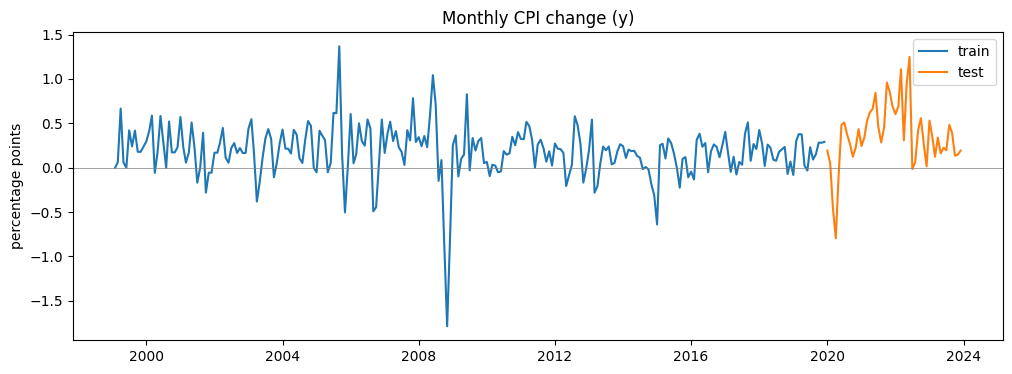

In [21]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(y_train.index, y_train, label="train", color="tab:blue")
ax.plot(y_test.index, y_test, label="test", color="tab:orange")
ax.axhline(0, color="grey", lw=0.5)
ax.set_title("Monthly CPI change (y)")
ax.set_ylabel("percentage points")
ax.legend()
plt.show()

### What do we see?

- `y` is usually small and positive: around **0.2 points per month** (about 2.4% per year).
- There are a few big drops: late 2008 (oil price crash) and spring 2020 (COVID).
- The **test period is unusual**: first the COVID drop, then the 2021-2022 inflation surge, with months above 1 point. So the test is harder than most training years.

## 2. Benchmarks with no model

**What:** two very simple "predictions" that need no machine learning:
- **naive**: this month will be like last month (`y_lag1`).
- **training mean**: this month will be like the average month in train.

**Why:** a model is only useful if it beats these. We compute their errors on **train only** for now, just to get a sense of scale. (RMSE and MAE are explained in step 3.)

In [22]:
naive_train_pred = train_df["y_lag1"]

naive_train_rmse = root_mean_squared_error(y_train, naive_train_pred)
naive_train_mae = mean_absolute_error(y_train, naive_train_pred)
print(f"Naive (y_lag1)  - train RMSE: {naive_train_rmse:.4f} | MAE: {naive_train_mae:.4f}")

Naive (y_lag1)  - train RMSE: 0.3114 | MAE: 0.2226


In [23]:
train_mean = y_train.mean()
mean_train_pred = np.full(len(y_train), train_mean)

mean_train_rmse = root_mean_squared_error(y_train, mean_train_pred)
mean_train_mae = mean_absolute_error(y_train, mean_train_pred)
print(f"Training mean = {train_mean:.4f}")
print(f"Training mean   - train RMSE: {mean_train_rmse:.4f} | MAE: {mean_train_mae:.4f}")

Training mean = 0.1798
Training mean   - train RMSE: 0.2863 | MAE: 0.1921


### What do we see?

A surprise: on train, the **naive** forecast (RMSE 0.311) is **worse** than just predicting the average month (RMSE 0.286).

Monthly CPI changes are noisy and jump around, so "same as last month" is not a great guide. These two numbers give us the scale: a useful model should have an RMSE clearly below ~0.29 on train.

## 3. Metrics: MSE, RMSE and MAE

**What:** the error of one prediction is `error = actual - predicted`. We summarise many errors with:
- **MSE** (mean squared error): average of the squared errors. Big errors count a lot.
- **RMSE** = square root of MSE. Same units as `y` (percentage points of monthly CPI), so it is easy to read.
- **MAE** (mean absolute error): average of the absolute errors. Less sensitive to a few big errors.

**Why:** we need one number to compare models. Let's try a tiny example with 4 numbers, first by hand and then with sklearn.

In [24]:
y_true_example = np.array([0.2, 0.1, 0.4, 0.3])
y_pred_example = np.array([0.3, 0.1, 0.2, 0.3])

errors_example = y_true_example - y_pred_example
print("errors:        ", errors_example)
print("squared errors:", errors_example ** 2)
print("abs errors:    ", np.abs(errors_example))

errors:         [-0.1  0.   0.2  0. ]
squared errors: [0.01 0.   0.04 0.  ]
abs errors:     [0.1 0.  0.2 0. ]


In [25]:
mse_by_hand = np.mean(errors_example ** 2)
rmse_by_hand = np.sqrt(mse_by_hand)
mae_by_hand = np.mean(np.abs(errors_example))

print(f"By hand -> MSE: {mse_by_hand:.4f} | RMSE: {rmse_by_hand:.4f} | MAE: {mae_by_hand:.4f}")

By hand -> MSE: 0.0125 | RMSE: 0.1118 | MAE: 0.0750


In [26]:
mse_sklearn = mean_squared_error(y_true_example, y_pred_example)
rmse_sklearn = root_mean_squared_error(y_true_example, y_pred_example)
mae_sklearn = mean_absolute_error(y_true_example, y_pred_example)

print(f"sklearn -> MSE: {mse_sklearn:.4f} | RMSE: {rmse_sklearn:.4f} | MAE: {mae_sklearn:.4f}")

sklearn -> MSE: 0.0125 | RMSE: 0.1118 | MAE: 0.0750


### What do we see?

Both ways give the same numbers. Notice that RMSE (0.112) is bigger than MAE (0.075): the one big error (0.2) weighs more once it is squared.

**How we use the metrics in this project**
- Each model, when it learns, **minimizes squared error** internally (that is what Linear Regression, Random Forest and XGBoost with `reg:squarederror` do).
- We use **RMSE** to compare models and to choose hyperparameters, because it is in the same units as `y`.
- We also report **MAE**, as a second view that is less driven by a few big months.

## 4. Why not a random split?

**What:** to choose hyperparameters we need *validation* data inside train. Normally we would use a random K-fold.

**Why not here:** with time series, a random split would let the model learn from the future (e.g. train on 2015 and validate on 2010). That is cheating, and it makes the errors look smaller than they really are.

`TimeSeriesSplit` always trains on the past and validates on the months right after it. Each fold has a bigger train part.

In [27]:
tscv = TimeSeriesSplit(n_splits=N_SPLITS)

fold = 1
for train_idx, val_idx in tscv.split(X_train):
    train_dates = X_train.index[train_idx]
    val_dates = X_train.index[val_idx]
    print(f"Fold {fold}: train {train_dates.min():%Y-%m} to {train_dates.max():%Y-%m} "
          f"({len(train_idx)} months) | validation {val_dates.min():%Y-%m} to {val_dates.max():%Y-%m} "
          f"({len(val_idx)} months)")
    fold = fold + 1

Fold 1: train 1999-02 to 2002-11 (46 months) | validation 2002-12 to 2006-04 (41 months)
Fold 2: train 1999-02 to 2006-04 (87 months) | validation 2006-05 to 2009-09 (41 months)
Fold 3: train 1999-02 to 2009-09 (128 months) | validation 2009-10 to 2013-02 (41 months)
Fold 4: train 1999-02 to 2013-02 (169 months) | validation 2013-03 to 2016-07 (41 months)
Fold 5: train 1999-02 to 2016-07 (210 months) | validation 2016-08 to 2019-12 (41 months)


### What do we see?

Validation is always **after** the training part, and the training part grows fold by fold. The test period (2020-2023) does not appear at all: cross-validation only uses train.

## 5. What is a Pipeline?

**What:** some models (like Linear Regression) work better when all features are on the same scale. `StandardScaler` does this: it subtracts the mean and divides by the standard deviation of each column.

**Why it matters:** the mean and std must be learned **from train only**. Let's do it step by step first.

In [28]:
scaler = StandardScaler()
scaler.fit(X_train)

X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Means learned from train (first 4 features):")
print(pd.Series(scaler.mean_, index=FEATURES).head(4).round(3))

Means learned from train (first 4 features):
y_lag1    0.179
y_lag2    0.179
y_lag3    0.178
y_ma12    0.179
dtype: float64


In [29]:
X_train_scaled = pd.DataFrame(X_train_scaled, columns=FEATURES, index=X_train.index)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=FEATURES, index=X_test.index)

print("Train after scaling: mean and std (first 4 features)")
print(X_train_scaled.iloc[:, :4].agg(["mean", "std"]).round(3))
print()
print("Test after scaling: mean and std (first 4 features)")
print(X_test_scaled.iloc[:, :4].agg(["mean", "std"]).round(3))

Train after scaling: mean and std (first 4 features)
      y_lag1  y_lag2  y_lag3  y_ma12
mean  -0.000  -0.000  -0.000   0.000
std    1.002   1.002   1.002   1.002

Test after scaling: mean and std (first 4 features)
      y_lag1  y_lag2  y_lag3  y_ma12
mean   0.670   0.681   0.694   1.872
std    1.265   1.261   1.256   2.173


### What do we see?

Train has mean 0 and std 1 exactly (that is how the scaler was fitted). Test does **not**, and that is normal: test is new data that the scaler never saw.

**The leakage problem:** if we fitted the scaler on train + test together, the mean and std would contain information from the future (2020-2023). Our model would then be "helped" by data it could not have in real life. Look how different the means are:

In [30]:
leaky_scaler = StandardScaler()
leaky_scaler.fit(pd.concat([X_train, X_test]))

compare_means = pd.DataFrame({
    "mean_train_only": scaler.mean_,
    "mean_train_and_test (leaky)": leaky_scaler.mean_,
}, index=FEATURES)
compare_means.round(3)

,mean_train_only,mean_train_and_test (leaky)
y_lag1,0.179,0.210
y_lag2,0.179,0.210
y_lag3,0.178,0.210
y_ma12,0.179,0.208
cpi_core_chg_ma12,0.166,0.192
cpi_core_chg,0.165,0.193
ppi_chg,0.192,0.242
housing_chg,-0.112,-0.055
payems_chg,0.069,0.069
oil_mean_chg,0.623,0.585


A **Pipeline** joins the steps (scaler + model) into one object. When we call `fit`, it fits the scaler and the model on the data we give it, and nothing else. Inside cross-validation this means: in every fold the scaler only sees that fold's training part. No leakage, and no manual work.

In [31]:
demo_pipe = make_pipeline(StandardScaler(), LinearRegression())
demo_pipe

,steps,"[('standardscaler', ...), ('linearregression', ...)]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None


In [32]:
demo_pipe.fit(X_train, y_train)

pipe_scaler = demo_pipe.named_steps["standardscaler"]
print("Same means as our manual scaler?", np.allclose(pipe_scaler.mean_, scaler.mean_))

Same means as our manual scaler? True


## 6. Model 1: Linear Regression

**What:** `make_pipeline(StandardScaler(), LinearRegression())`. There are no hyperparameters to tune.

**Why:** it is the simplest model, a good first reference. We measure it with `cross_val_score` and `TimeSeriesSplit`. sklearn gives *negative* RMSE (because it always maximises scores), so we flip the sign.

In [33]:
linear_pipe = make_pipeline(StandardScaler(), LinearRegression())

linear_scores = cross_val_score(
    linear_pipe, X_train, y_train,
    cv=tscv,
    scoring="neg_root_mean_squared_error",
)
linear_cv_rmse = -linear_scores

print("RMSE per fold:", linear_cv_rmse.round(4))
print(f"Mean CV RMSE: {linear_cv_rmse.mean():.4f}")
print(f"Std CV RMSE:  {linear_cv_rmse.std():.4f}")

RMSE per fold: [0.2684 0.2548 0.1314 0.1413 0.1196]
Mean CV RMSE: 0.1831
Std CV RMSE:  0.0646


### What do we see?

- The error changes a lot from fold to fold: about **0.26** in the first two folds (validation 2002-2009, which includes the 2008 crash) and about **0.12-0.14** in the later, calmer folds.
- The mean CV RMSE (**0.183**) is well below both benchmarks (~0.29-0.31), so the features really help.
- The std is large (0.065): the result depends a lot on which years we validate on.

## 7. Model 2: Random Forest

**What:** a Random Forest inside a Pipeline, with a small grid of hyperparameters chosen by `GridSearchCV` + `TimeSeriesSplit`:
- `n_estimators`: number of trees.
- `max_depth`: how deep each tree can grow (deeper = more complex).
- `min_samples_leaf`: minimum months in each leaf (bigger = smoother).

**Why no scaler:** trees split on thresholds like "oil change > 3%". Changing the scale of a column does not change which split is best, so scaling is not needed.

We keep the Pipeline anyway: same structure for every model, and easy to add steps later.

In [34]:
rf_pipe = Pipeline([
    ("model", RandomForestRegressor(random_state=SEED)),
])

rf_grid = {
    "model__n_estimators": [200],
    "model__max_depth": [3, 5, None],
    "model__min_samples_leaf": [1, 5, 10],
}
print("Combinations to try:", 1 * 3 * 3)

Combinations to try: 9


In [36]:
rf_search = GridSearchCV(
    rf_pipe,
    rf_grid,
    cv=tscv,
    scoring="neg_root_mean_squared_error",
)
rf_search.fit(X_train, y_train)

rf_cv_rmse = -rf_search.best_score_
rf_cv_std = rf_search.cv_results_["std_test_score"][rf_search.best_index_]
print("Best parameters:", rf_search.best_params_)
print(f"Best CV RMSE: {rf_cv_rmse:.4f} (std {rf_cv_std:.4f})")

Best parameters: {'model__max_depth': 5, 'model__min_samples_leaf': 1, 'model__n_estimators': 200}
Best CV RMSE: 0.1868 (std 0.0796)


### What do we see?

The best forest uses `max_depth=5` and `min_samples_leaf=1`. Its CV RMSE (**0.187**) is very close to the Linear Regression (0.183): the extra flexibility of the trees does not help much here.

## 8. Model 3: XGBoost

**What:** same structure as the Random Forest, with `XGBRegressor`. Grid:
- `n_estimators`: number of trees.
- `max_depth`: depth of each tree (XGBoost works well with shallow trees).
- `learning_rate`: how much each new tree corrects the previous ones (smaller = slower, more careful).

**Why:** boosting often beats a Random Forest on tabular data. Let's check if that is true here.

The next cell installs `xgboost` only if it is missing.

In [37]:
try:
    import xgboost
except ImportError:
    %pip install xgboost

import xgboost
print("xgboost version:", xgboost.__version__)

xgboost version: 3.2.0


In [38]:
from xgboost import XGBRegressor

# n_jobs=1: on this tiny dataset, using all CPU cores makes XGBoost much slower
xgb_pipe = Pipeline([
    ("model", XGBRegressor(random_state=SEED, objective="reg:squarederror", n_jobs=1)),
])

xgb_grid = {
    "model__n_estimators": [100, 300],
    "model__max_depth": [2, 3],
    "model__learning_rate": [0.03, 0.1],
}
print("Combinations to try:", 2 * 2 * 2)

Combinations to try: 8


In [39]:
xgb_search = GridSearchCV(
    xgb_pipe,
    xgb_grid,
    cv=tscv,
    scoring="neg_root_mean_squared_error",
)
xgb_search.fit(X_train, y_train)

xgb_cv_rmse = -xgb_search.best_score_
xgb_cv_std = xgb_search.cv_results_["std_test_score"][xgb_search.best_index_]
print("Best parameters:", xgb_search.best_params_)
print(f"Best CV RMSE: {xgb_cv_rmse:.4f} (std {xgb_cv_std:.4f})")

Best parameters: {'model__learning_rate': 0.03, 'model__max_depth': 2, 'model__n_estimators': 300}
Best CV RMSE: 0.1866 (std 0.0759)


## 9. Compare the 3 models (train data only)

**What:** put the cross-validation RMSE of the 3 models side by side.

**Why:** this is how we choose between models **without touching the test set**.

In [40]:
cv_comparison = pd.DataFrame({
    "model": ["Linear Regression", "Random Forest", "XGBoost"],
    "cv_rmse_mean": [linear_cv_rmse.mean(), rf_cv_rmse, xgb_cv_rmse],
    "cv_rmse_std": [linear_cv_rmse.std(), rf_cv_std, xgb_cv_std],
})
cv_comparison.round(4)

,model,cv_rmse_mean,cv_rmse_std
0,Linear Regression,0.1831,0.0646
1,Random Forest,0.1868,0.0796
2,XGBoost,0.1866,0.0759


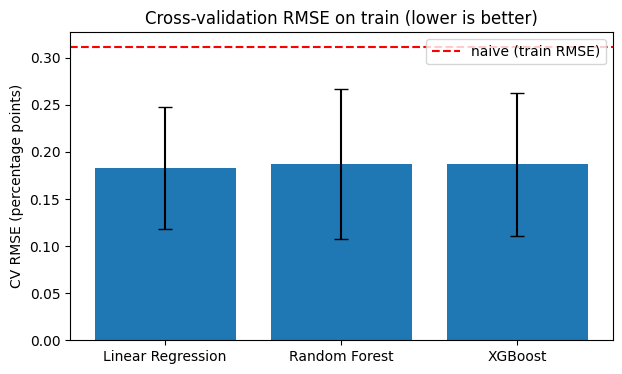

In [41]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(cv_comparison["model"], cv_comparison["cv_rmse_mean"],
       yerr=cv_comparison["cv_rmse_std"], capsize=5, color="tab:blue")
ax.axhline(naive_train_rmse, color="red", ls="--", label="naive (train RMSE)")
ax.set_ylabel("CV RMSE (percentage points)")
ax.set_title("Cross-validation RMSE on train (lower is better)")
ax.legend()
plt.show()

### What do we see?

- The 3 models are **almost tied**: CV RMSE between 0.183 and 0.187.
- The differences between models are much smaller than the std across folds (~0.07). With this data, cross-validation **cannot say that one model is clearly better**.
- Linear Regression is slightly ahead and it is the simplest model.
- All 3 clearly beat the naive benchmark (red line).

## 10. Learning curves

**What:** for each model (with its best parameters), we train on bigger and bigger parts of the training data and plot two lines:
- **training RMSE**: error on the data the model learned from.
- **validation RMSE**: error on the next months (unseen).

**How to read it**
- **Big gap** between the two lines: the model memorises the training data → **overfitting**.
- **Both lines high**: the model is too simple → **underfitting**.
- **Validation line still going down** at the right: **more data would help**.

⚠️ We only have ~250 training months, so the curves are noisy. Look at the general shape, not at small bumps.

**A detail about `TimeSeriesSplit` here:** `learning_curve` measures the training sizes on the **first** fold. With `TimeSeriesSplit`, the first fold has only 46 months, so the curve would stop at 46 months. To see the whole picture we give `learning_curve` the **last** fold of our `TimeSeriesSplit`: train 1999-2016 (210 months), validation 2016-2019. The model always trains on the oldest months first and is always validated on the same, later months.

In [42]:
best_pipelines = {
    "Linear Regression": linear_pipe,
    "Random Forest": rf_search.best_estimator_,
    "XGBoost": xgb_search.best_estimator_,
}
print(list(best_pipelines.keys()))

['Linear Regression', 'Random Forest', 'XGBoost']


In [43]:
all_folds = list(TimeSeriesSplit(N_SPLITS).split(X_train))
last_train_idx, last_val_idx = all_folds[-1]
last_fold = [(last_train_idx, last_val_idx)]

print("Learning-curve train part:", len(last_train_idx), "months")
print("Learning-curve validation:", len(last_val_idx), "months,",
      f"{X_train.index[last_val_idx].min():%Y-%m} to {X_train.index[last_val_idx].max():%Y-%m}")

Learning-curve train part: 210 months
Learning-curve validation: 41 months, 2016-08 to 2019-12


Linear Regression: validation RMSE by size [0.152 0.135 0.133 0.122 0.12 ]
Random Forest: validation RMSE by size [0.113 0.116 0.124 0.11  0.112]
XGBoost: validation RMSE by size [0.117 0.121 0.12  0.106 0.106]


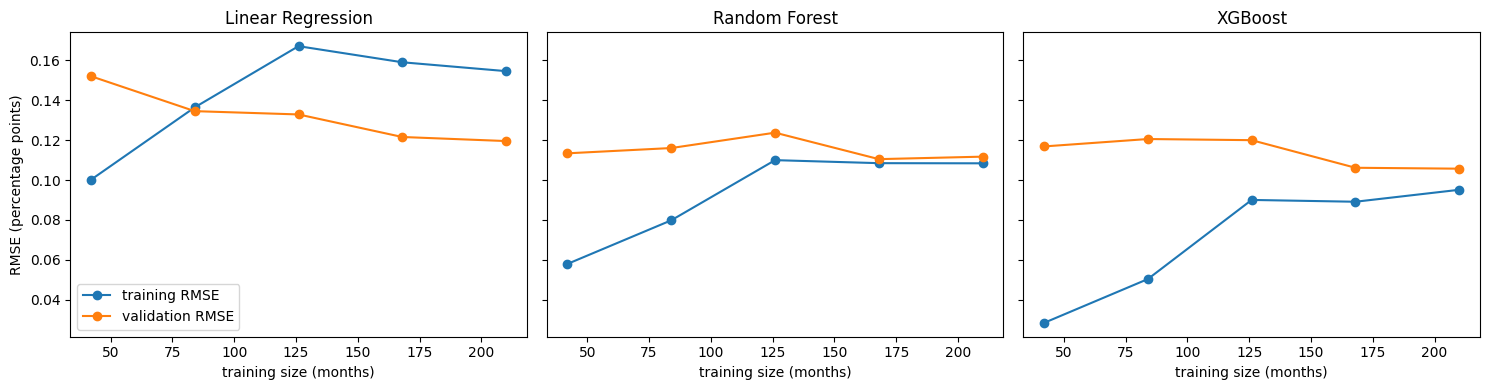

In [44]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

for ax, (name, pipe) in zip(axes, best_pipelines.items()):
    sizes, train_scores, val_scores = learning_curve(
        pipe, X_train, y_train,
        cv=last_fold,
        scoring="neg_root_mean_squared_error",
        train_sizes=np.linspace(0.2, 1.0, 5),
    )
    train_rmse = -train_scores.mean(axis=1)
    val_rmse = -val_scores.mean(axis=1)

    ax.plot(sizes, train_rmse, marker="o", label="training RMSE")
    ax.plot(sizes, val_rmse, marker="o", label="validation RMSE")
    ax.set_title(name)
    ax.set_xlabel("training size (months)")
    print(f"{name}: validation RMSE by size {val_rmse.round(3)}")

axes[0].set_ylabel("RMSE (percentage points)")
axes[0].legend()
plt.tight_layout()
plt.show()

### What do we see?

- **Random Forest and XGBoost:** with little data, the training RMSE is very low and far from the validation RMSE (overfitting). With more data the gap closes, and at 210 months the two lines are close. So with all the data, overfitting is small.
- **Linear Regression:** the training line is *above* the validation line. This is not a bug. The validation months (2016-2019) were very calm, while the training months include 2008, which is hard to fit. The validation line keeps going slowly down, so more data helps the linear model a little.
- For the trees, the validation line is almost flat at the end: more data of the same kind would not help much.
- Remember: one validation window and ~250 months, so these are noisy curves. Do not read too much into small bumps.

## 11. Final evaluation on the test set

> ⚠️ **Here we touch the test set for the first and only time.**
>
> Everything is now fixed: the features, the models and their hyperparameters. We do **not** go back to change anything after seeing these results. If we did, the test set would stop being a fair test.

**What:** fit each final pipeline on **all** the training data and predict the test months (2020-2023).

In [45]:
linear_final = clone(linear_pipe)
linear_final.fit(X_train, y_train)

rf_final = clone(rf_search.best_estimator_)
rf_final.fit(X_train, y_train)

xgb_final = clone(xgb_search.best_estimator_)
xgb_final.fit(X_train, y_train)

print("3 final pipelines fitted on", len(X_train), "training months")

3 final pipelines fitted on 251 training months


In [46]:
test_predictions = pd.DataFrame(index=test_df.index)
test_predictions["y"] = y_test
test_predictions["naive_lag1"] = test_df["y_lag1"]
test_predictions["train_mean"] = train_mean
test_predictions["linear_macro"] = linear_final.predict(X_test)
test_predictions["rf_macro"] = rf_final.predict(X_test)
test_predictions["xgb_macro"] = xgb_final.predict(X_test)
test_predictions.head()

,y,naive_lag1,train_mean,linear_macro,rf_macro,xgb_macro
date,,,,,,
2020-01-01,0.191982,0.290799,0.17979,0.156207,0.158792,0.144500
2020-02-01,0.047456,0.191982,0.17979,0.000512,0.004807,0.018120
2020-03-01,-0.453873,0.047456,0.17979,-0.290359,-0.187372,-0.219316
2020-04-01,-0.795168,-0.453873,0.17979,-0.809841,-0.912254,-1.245220
2020-05-01,-0.089873,-0.795168,0.17979,-0.588832,0.155162,0.073548


We compute RMSE and MAE for the full test period, and separately for 2020-2021 (COVID) and 2022-2023 (high inflation), because these two periods are very different.

In [47]:
periods = {
    "full": ("2020-01-01", "2023-12-31"),
    "2020_2021": ("2020-01-01", "2021-12-31"),
    "2022_2023": ("2022-01-01", "2023-12-31"),
}
model_names = {
    "naive_lag1": "Naive (y_lag1)",
    "train_mean": "Training mean",
    "linear_macro": "Linear Regression",
    "rf_macro": "Random Forest",
    "xgb_macro": "XGBoost",
}

rows = []
for column, name in model_names.items():
    row = {"model": name}
    for period, (start, end) in periods.items():
        part = test_predictions.loc[start:end]
        row[f"rmse_{period}"] = root_mean_squared_error(part["y"], part[column])
        row[f"mae_{period}"] = mean_absolute_error(part["y"], part[column])
    rows.append(row)

results = pd.DataFrame(rows)
results.round(4)

,model,rmse_full,mae_full,rmse_2020_2021,mae_2020_2021,rmse_2022_2023,mae_2022_2023
0,Naive (y_lag1),0.3467,0.2538,0.2852,0.2240,0.3988,0.2836
1,Training mean,0.4058,0.3015,0.4210,0.3358,0.3901,0.2671
2,Linear Regression,0.2055,0.1570,0.2229,0.1634,0.1864,0.1507
3,Random Forest,0.2249,0.1716,0.2260,0.1728,0.2239,0.1704
4,XGBoost,0.2541,0.1988,0.2711,0.2195,0.2359,0.1781


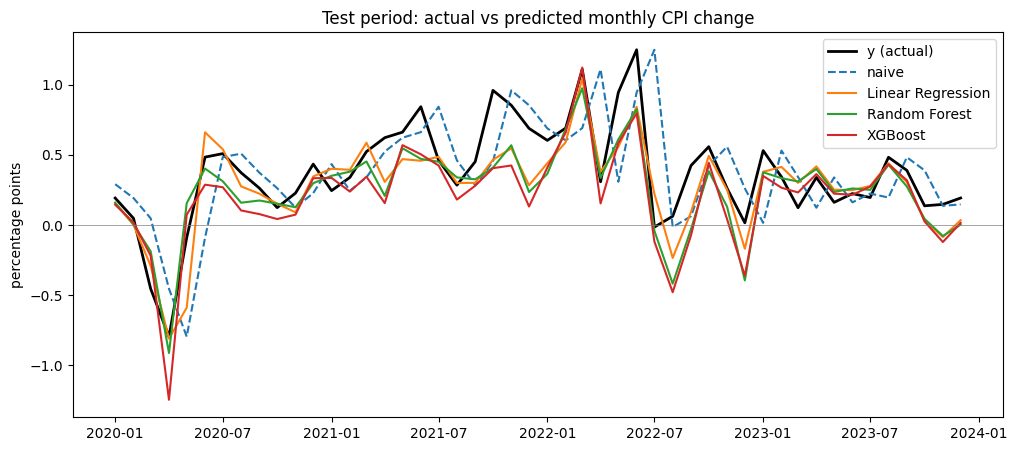

In [48]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(test_predictions.index, test_predictions["y"], color="black", lw=2, label="y (actual)")
ax.plot(test_predictions.index, test_predictions["naive_lag1"], ls="--", label="naive")
ax.plot(test_predictions.index, test_predictions["linear_macro"], label="Linear Regression")
ax.plot(test_predictions.index, test_predictions["rf_macro"], label="Random Forest")
ax.plot(test_predictions.index, test_predictions["xgb_macro"], label="XGBoost")
ax.axhline(0, color="grey", lw=0.5)
ax.set_title("Test period: actual vs predicted monthly CPI change")
ax.set_ylabel("percentage points")
ax.legend()
plt.show()

### What do we see?

- **Linear Regression is the best on test** (RMSE 0.206), then Random Forest (0.225) and XGBoost (0.254). This is the same order as in cross-validation, but the gaps are bigger now.
- **All 3 models beat both benchmarks by a lot** (naive 0.347, training mean 0.406).
- The **training mean is now the worst**: in 2021-2023 inflation was far above the 1999-2019 average, and a fixed average cannot follow that.
- In 2022-2023 the Linear Regression does even better (0.186). In the plot, the models follow the big swings well, because they see this month's gasoline and oil prices.
- XGBoost overshoots April 2020 (-1.25 predicted vs -0.80 actual).

We do **not** change anything because of these results. The ranking is a result, not a choice.

## 12. Interpretation

**What:** look inside the fitted models.
- **Linear Regression coefficients**: because the features are standardized inside the pipeline, each coefficient means "change in `y` when this feature goes up by 1 standard deviation". So we can compare them with each other.
- **Random Forest feature importances**: how much each feature helped the trees reduce the error.

⚠️ Importances show neither **direction** (up or down) nor **causality**. A coefficient is not causal either: it is a correlation, holding the other features fixed.

In [49]:
linear_model = linear_final.named_steps["linearregression"]
linear_coefs = pd.Series(linear_model.coef_, index=FEATURES).sort_values()
linear_coefs.round(4)

y_lag2              -0.0263
ppi_chg             -0.0005
housing_chg         -0.0000
cpi_core_chg_ma12    0.0046
cpi_core_chg         0.0055
y_lag3               0.0075
payems_chg           0.0080
exp                  0.0096
y_ma12               0.0115
oil_mean_chg         0.0255
y_lag1               0.0579
gas_mean_chg         0.2038
dtype: float64

In [50]:
rf_model = rf_final.named_steps["model"]
rf_importances = pd.Series(rf_model.feature_importances_, index=FEATURES).sort_values()
rf_importances.round(4)

housing_chg          0.0098
cpi_core_chg_ma12    0.0109
payems_chg           0.0112
exp                  0.0119
y_lag3               0.0137
y_lag2               0.0156
cpi_core_chg         0.0192
y_ma12               0.0279
ppi_chg              0.0286
oil_mean_chg         0.0408
y_lag1               0.0576
gas_mean_chg         0.7529
dtype: float64

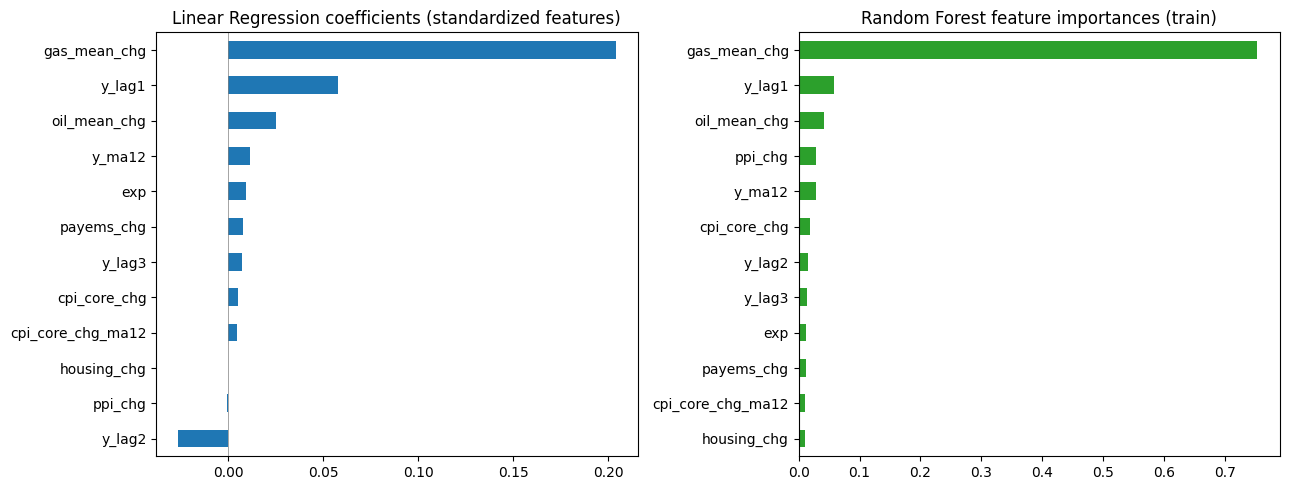

In [51]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

linear_coefs.plot.barh(ax=axes[0], color="tab:blue")
axes[0].axvline(0, color="grey", lw=0.5)
axes[0].set_title("Linear Regression coefficients (standardized features)")

rf_importances.plot.barh(ax=axes[1], color="tab:green")
axes[1].set_title("Random Forest feature importances (train)")

plt.tight_layout()
plt.show()

### What do we see?

- Both models agree: **`gas_mean_chg` (this month's gasoline price change) is by far the most important feature**: coefficient 0.20 per standard deviation, and 75% of the Random Forest importance.
- Then come `y_lag1` (last month's CPI) and `oil_mean_chg`. Everything else is close to zero.
- This makes sense: energy is the most volatile part of CPI, and gasoline prices for month t are already known at the end of month t.
- Be careful: gasoline and oil move together, so the Linear Regression "shares" the credit between them in a way that is not very stable.

## 13. Save predictions and results

**What:** save the test predictions and the results table, so the next notebooks can compare against this baseline.

In [52]:
predictions_out = test_predictions[["y", "naive_lag1", "linear_macro", "rf_macro", "xgb_macro"]]
predictions_out = predictions_out.rename_axis("month").reset_index()
predictions_out.to_csv(DATA_DIR / "model_predictions_macro.csv", index=False)
print("Saved:", DATA_DIR / "model_predictions_macro.csv", predictions_out.shape)

Saved: /home/nvela/code/nvelasquez1551/can-news-nowcast-inflation/processed_data/model_predictions_macro.csv (48, 6)


In [53]:
results.to_csv(DATA_DIR / "results_macro.csv", index=False)
print("Saved:", DATA_DIR / "results_macro.csv", results.shape)

Saved: /home/nvela/code/nvelasquez1551/can-news-nowcast-inflation/processed_data/results_macro.csv (5, 7)


## 14. (OPTIONAL) Expanding refit

> This section is **optional**. It does not change the saved files.

**What:** in real life, every month we would retrain the model with the new data that just arrived. Here, for each test month t, we refit each model on **all months before t** (with the **same, fixed** hyperparameters) and predict t.

**Why:** step 11 trained once on 1999-2019 and never updated. This shows if updating the model every month helps. Nothing is tuned here.

In [54]:
final_pipelines = {
    "linear_macro": linear_final,
    "rf_macro": rf_final,
    "xgb_macro": xgb_final,
}

expanding_predictions = pd.DataFrame(index=test_df.index)
expanding_predictions["y"] = y_test

for column, pipe in final_pipelines.items():
    preds = []
    for t in test_df.index:
        history = df[df.index < t]
        model = clone(pipe)
        model.fit(history[FEATURES], history["y"])
        preds.append(model.predict(df.loc[[t], FEATURES])[0])
    expanding_predictions[column] = preds
    print("done:", column)

expanding_predictions.head()

done: linear_macro
done: rf_macro
done: xgb_macro


,y,linear_macro,rf_macro,xgb_macro
date,,,,
2020-01-01,0.191982,0.156207,0.158792,0.144500
2020-02-01,0.047456,0.001161,0.003814,0.016614
2020-03-01,-0.453873,-0.285770,-0.181022,-0.220505
2020-04-01,-0.795168,-0.832787,-0.909586,-1.259331
2020-05-01,-0.089873,-0.463648,0.163091,0.097858


In [ ]:
refit_comparison = pd.DataFrame({
    "rmse_fit_once": [root_mean_squared_error(y_test, test_predictions[c]) for c in final_pipelines],
    "rmse_expanding": [root_mean_squared_error(y_test, expanding_predictions[c]) for c in final_pipelines],
}, index=list(final_pipelines))
refit_comparison.round(4)

### What do we see?

- **Refitting every month helps all 3 models**: Linear Regression 0.206 → 0.185, Random Forest 0.225 → 0.208, XGBoost 0.254 → 0.222.
- The models learn from the 2020-2023 months as they arrive, which matters a lot when the economy changes as much as it did in those years.
- This is closer to how a real nowcast would run. The saved files still contain the fit-once results from step 11, as decided.